# 01 - Exploratory Data Analysis

Dataset: `data/processed/training_dataset.csv` (data **synthetic**, bukan data operasional Gymnasium).
Notebook ini hanya memanggil fungsi dari `src/ml/eda.py` agar logika tidak terduplikasi.

In [1]:
import sys
sys.path.append("..")
import pandas as pd
from IPython.display import display
from src.ml import eda
from src.ml.feature_engineering import FEATURE_COLUMNS, LABEL_COLUMN

df = pd.read_csv("../data/processed/training_dataset.csv", parse_dates=["reference_date"])
print(df.shape)
display(df.head())

(1304, 17)


,customer_id,reference_date,attendance_rate_30d,attendance_rate_90d,absent_count_30d,consecutive_absences,reschedule_count_90d,reminder_response_rate,no_response_streak,avg_response_time_hours,days_since_last_attendance,days_since_last_reminder,tenure_days,persona,favorite_class_type,n_history_events,priority
0,1,2026-05-21,0.944444,0.923077,1.0,1.0,0.0,0.275862,0.0,4.942960,1.583333,0.544444,258.0,menengah_atas,group_class,165,Low
1,1,2026-06-24,0.944444,0.903846,1.0,0.0,0.0,0.283186,0.0,4.900023,0.229167,0.708333,292.0,menengah_atas,group_class,211,Low
2,1,2026-08-04,0.928571,0.893617,1.0,0.0,1.0,0.291971,0.0,5.220300,2.333333,0.297917,333.0,menengah_atas,group_class,254,Low
3,1,2026-08-26,0.777778,0.836735,4.0,0.0,1.0,NaN,0.0,5.347926,0.229167,1.307639,355.0,menengah_atas,group_class,282,Low
4,2,2026-05-24,0.400000,0.307692,3.0,2.0,0.0,0.666667,1.0,4.568921,15.645833,0.559722,157.0,ibu-ibu,group_class,46,Low


In [2]:
print("Jumlah customer unik:", df.customer_id.nunique())
print("Snapshot per customer:", df.groupby("customer_id").size().value_counts().sort_index().to_dict())
display(df[FEATURE_COLUMNS].describe().T.round(2))

Jumlah customer unik: 400
Snapshot per customer: {1: 12, 2: 25, 3: 210, 4: 153}


,count,mean,std,min,25%,50%,75%,max
attendance_rate_30d,1296.0,0.60,0.28,0.00,0.40,0.60,0.80,1.00
attendance_rate_90d,1296.0,0.60,0.25,0.00,0.40,0.60,0.81,1.00
absent_count_30d,1304.0,2.86,2.61,0.00,1.00,2.00,4.00,15.00
consecutive_absences,1304.0,0.87,1.69,0.00,0.00,0.00,1.00,17.00
reschedule_count_90d,1304.0,1.90,2.44,0.00,0.00,1.00,3.00,16.00
reminder_response_rate,1268.0,0.57,0.25,0.00,0.40,0.60,0.76,1.00
no_response_streak,1304.0,1.12,2.55,0.00,0.00,0.00,1.00,24.00
avg_response_time_hours,1248.0,7.45,3.73,0.75,5.18,6.93,8.89,47.00
days_since_last_attendance,1296.0,6.14,7.90,0.21,1.62,3.62,6.65,74.58
days_since_last_reminder,1281.0,2.43,2.45,0.27,0.55,1.71,3.33,25.29


## 1. Distribusi kelas

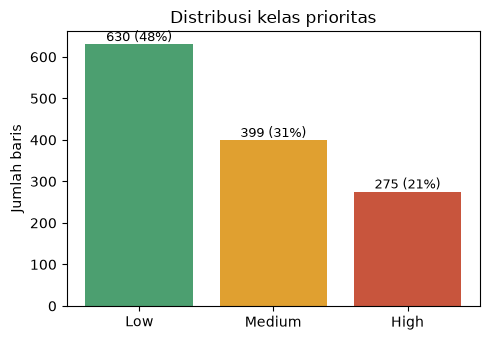

In [3]:
eda.plot_class_distribution(df);

**Interpretasi:** kelas tidak seimbang secara wajar (Low terbanyak, High paling sedikit sekitar 21%). Karena itu model memakai `class_weight='balanced'` dan evaluasi tidak boleh hanya akurasi: kelas High paling penting tetapi paling jarang.

## 2. Fitur utama per kelas

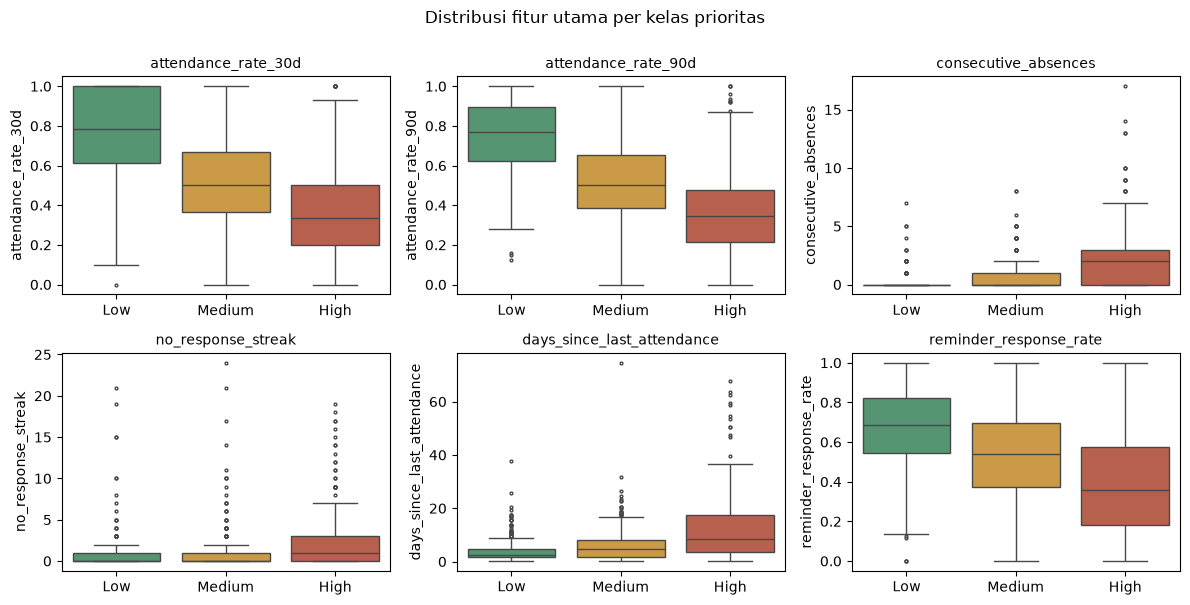

In [4]:
eda.plot_features_by_class(df);

In [5]:
display(df.groupby(LABEL_COLUMN)[["attendance_rate_30d", "attendance_rate_90d", "consecutive_absences",
                                    "no_response_streak", "days_since_last_attendance", "reminder_response_rate"]]
        .median().loc[["Low", "Medium", "High"]].round(2))

,attendance_rate_30d,attendance_rate_90d,consecutive_absences,no_response_streak,days_since_last_attendance,reminder_response_rate
priority,,,,,,
Low,0.79,0.77,0.0,0.0,2.65,0.69
Medium,0.50,0.50,0.0,0.0,4.58,0.54
High,0.33,0.34,2.0,1.0,8.60,0.36


**Interpretasi:** customer High punya kehadiran 30 hari yang jauh lebih rendah (median sekitar 0,33 dibanding 0,79 pada Low), lebih sering absen berturut-turut, dan lebih jarang merespons reminder. Arahnya sesuai logika bisnis. Namun sebaran antar kelas **saling tumpang tindih** (lihat boxplot): tidak ada satu fitur yang memisahkan kelas dengan sempurna, hasil dari faktor tersembunyi, noise, dan label yang di-flip saat pembuatan data.

## 3. Korelasi antar fitur

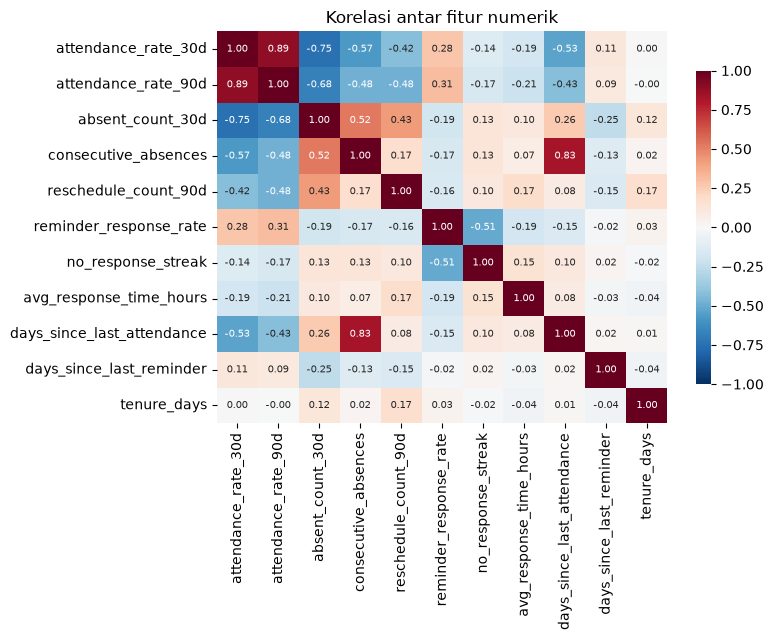

In [6]:
eda.plot_correlation(df);

**Interpretasi:** `attendance_rate_30d` dan `attendance_rate_90d` berkorelasi tinggi (sekitar 0,89), begitu pula `consecutive_absences` dengan `days_since_last_attendance` (sekitar 0,83). Fitur yang saling tumpang tindih ini membuat *permutation importance* terbagi di antara mereka (nilainya tampak kecil padahal informasinya penting). `tenure_days` hampir tidak berkorelasi dengan fitur lain.

## 4. Missing value

Baris cold start (riwayat < 3 kejadian): 32


,attendance_rate_30d,reminder_response_rate,avg_response_time_hours
n_history_events,,,
False,0.00,0.02,0.03
True,0.25,0.50,0.62


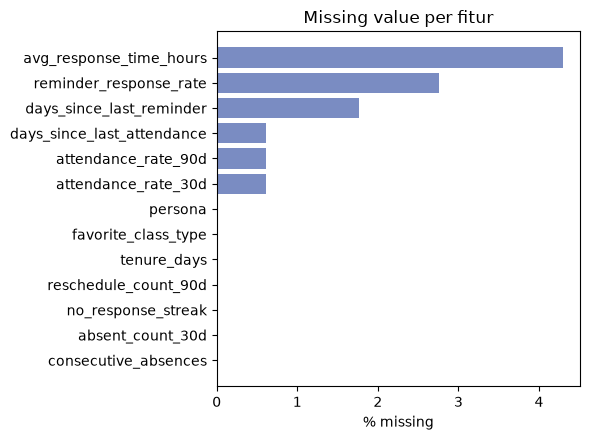

In [7]:
eda.plot_missing(df);
cold = df.n_history_events < 3
print("Baris cold start (riwayat < 3 kejadian):", int(cold.sum()))
display(df[["attendance_rate_30d", "reminder_response_rate", "avg_response_time_hours"]].isna().groupby(cold).mean().round(2))

**Interpretasi:** missing value terkonsentrasi pada customer baru yang belum punya riwayat (cold start), bukan tersebar acak, sehingga imputasi median di pipeline masuk akal dan customer cold start ditangani terpisah saat inference ("riwayat belum cukup").

## 5. Per persona

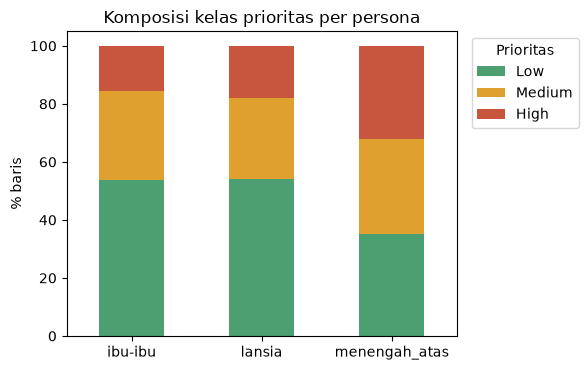

In [8]:
eda.plot_by_persona(df);

**Interpretasi:** persona `menengah_atas` memiliki porsi High paling besar (sekitar 32%, dibanding sekitar 17% pada ibu-ibu dan lansia), konsisten dengan asumsi simulasi bahwa kesibukan lebih tinggi. Persona dimasukkan sebagai fitur kategorikal dan juga dipakai nanti untuk memilih nada pesan Generative AI.

## Ringkasan EDA

- Kelas tidak seimbang -> pakai class_weight dan metrik per kelas (terutama recall High).
- Kehadiran dan respons reminder adalah sinyal utama, tetapi kelas tumpang tindih -> performa sempurna tidak diharapkan (dan akan mencurigakan).
- Beberapa fitur berkorelasi tinggi -> interpretasi importance harus hati-hati.
- Missing value berasal dari customer baru -> penanganan cold start terpisah.
- Satu customer punya 3-4 snapshot -> split train/test **wajib dikelompokkan per customer**.